<a href="https://colab.research.google.com/github/rivindu02/EN3160-Image-Processing-and-Computer-Vision/blob/main/Assignment02_Q3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [147]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [148]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def superimpose(src_path, dest_path, dest_points, feather_amount=15, opacity=1.0, blend_mode='normal'):
    """
    Superimposes an image using high-quality interpolation and robust,
    numerically stable blending modes.
    """
    src_img = cv2.imread(src_path)
    dest_img = cv2.imread(dest_path)

    if src_img is None or dest_img is None:
        print(f"❌ FAILED TO LOAD IMAGE. Check path.")
        return
    print(f"✔️ Loaded images. Processing with '{blend_mode}' blend...")

    # --- 1. High-Quality Warping ---
    h, w = src_img.shape[:2]
    src_points = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype='float32')
    dest_points = np.array(dest_points, dtype='float32')

    H, _ = cv2.findHomography(src_points, dest_points)

    # Use INTER_LANCZOS4 for the best quality during transformation
    warped_src = cv2.warpPerspective(
        src_img, H, (dest_img.shape[1], dest_img.shape[0]),
        flags=cv2.INTER_LANCZOS4
    )

    # --- 2. Create and Feather the Mask ---
    mask = np.zeros(dest_img.shape, dtype=np.uint8)
    cv2.fillConvexPoly(mask, dest_points.astype(int), (255, 255, 255))

    if feather_amount > 0:
        kernel_size = (feather_amount * 2) + 1
        mask = cv2.GaussianBlur(mask, (kernel_size, kernel_size), 0)

    # --- 3. Robust Blending Logic ---
    # Convert images and mask to float for calculation precision
    mask = (mask.astype(np.float32) / 255.0) * opacity
    warped_src = warped_src.astype(np.float32) / 255.0
    dest_img = dest_img.astype(np.float32) / 255.0

    # This is the blended layer (e.g., multiplied or overlaid pixels)
    blended_layer = np.zeros_like(dest_img)

    if blend_mode == 'multiply':
        # Formula: Base * Blend
        blended_layer = dest_img * warped_src

    elif blend_mode == 'overlay':
        # Formula: Complex, depends on whether the base color is light or dark
        # We create boolean masks to handle the two conditions separately
        dark_mask = dest_img < 0.8
        light_mask = ~dark_mask # Invert the dark mask

        # Apply the two different formulas using the masks
        blended_layer[dark_mask] = 2 * warped_src[dark_mask] * dest_img[dark_mask]
        blended_layer[light_mask] = 1 - 2 * (1 - warped_src[light_mask]) * (1 - dest_img[light_mask])

    else: # 'normal' blend mode
        blended_layer = warped_src

    # --- 4. Final Composite ---
    # Linearly interpolate between the blended layer and the original destination
    # using the feathered mask. Formula: Blend * Mask + Dest * (1 - Mask)
    final_img = blended_layer * mask + dest_img * (1.0 - mask)

    # Clip values to the valid range [0, 1] to prevent artifacts
    final_img = np.clip(final_img, 0, 1)

    # Convert back to 8-bit integer format for display
    final_img = (final_img * 255).astype(np.uint8)

    # --- Display Result ---
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Final Image (Blend Mode: {blend_mode.capitalize()})")
    plt.axis('off')
    plt.show()

✔️ Loaded images. Processing with 'normal' blend...


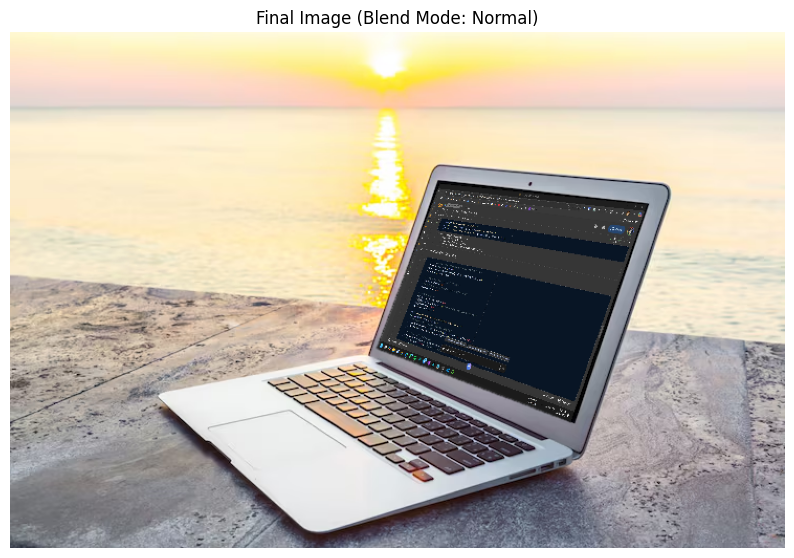

✔️ Loaded images. Processing with 'normal' blend...


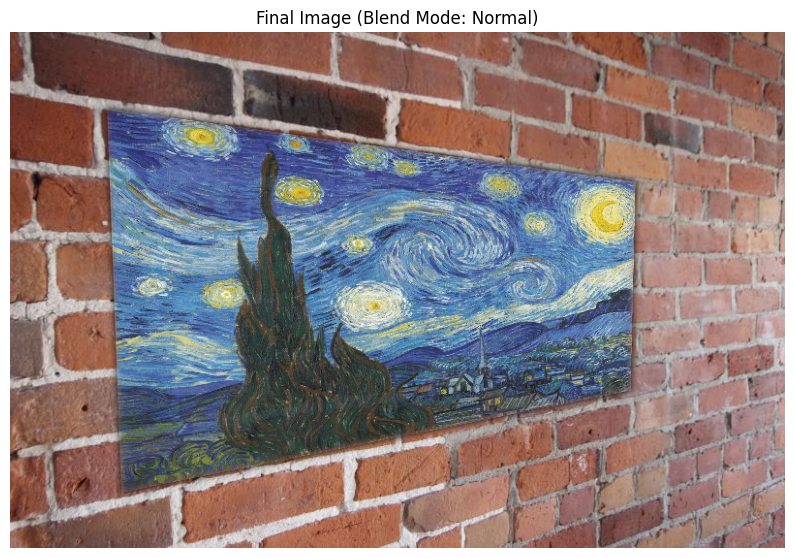

✔️ Loaded images. Processing with 'overlay' blend...


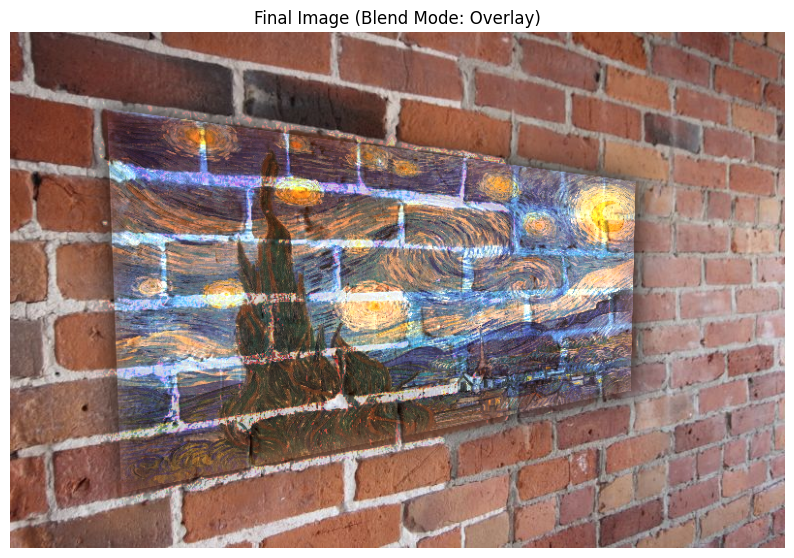

In [149]:
# Define the base path to your files in Google Drive
BASE_PATH = '/content/drive/My Drive/Colab Notebooks/'

# --- Example 1: Photorealistic Screen Replacement ---
laptop_screen_coords = [
    [410, 145],  # Top-Left corner
    [608, 165],  # Top-Right corner
    [535, 372],  # Bottom-Right corner
    [350, 302]   # Bottom-Left corner
]
superimpose(
    src_path=BASE_PATH + 'Screenshot.jpg',
    dest_path=BASE_PATH + 'laptop.jpg',
    dest_points=laptop_screen_coords,
    feather_amount=1,
    opacity=0.98,
    blend_mode='normal' # Normal blending is best for a screen
)

# --- Example 2: Photorealistic Wall Projection ---
wall_coords = [
    [100, 80], [645, 155], [640, 370], [115, 475]
]

superimpose(
    src_path=BASE_PATH + 'Starry_Night.jpg',
    dest_path=BASE_PATH + 'Brick_wall.jpg',
    dest_points=wall_coords,
    feather_amount=10,
    opacity=0.9,
    blend_mode='normal'
)
# Using 'overlay' for a vibrant blend that respects the wall's texture
superimpose(
    src_path=BASE_PATH + 'Starry_Night.jpg',
    dest_path=BASE_PATH + 'Brick_wall.jpg',
    dest_points=wall_coords,
    feather_amount=50,
    opacity=0.9,
    blend_mode='overlay'
)
